# **Assignment 1**


**Anja Pijak**  
ap72051@student.uni-lj.si


In [40]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import PolynomialFeatures

#### Data preparation


In [2]:
df = pd.read_csv("datasets/podatki_PM_a1.csv")
df.fillna(df.mean(), inplace=True)

# datum dropped manually

df.head()

,Glob_sevanje_mean,Hitrost_vetra_mean,Sunki_vetra_max,Padavine_sum,Vlaga_mean,Temperatura_Krvavec_mean,Temperatura_lokacija_mean,PM10,PM_vceraj,sinD,cosD
0,0.125,0.6750,2.9,0.0,79.1750,-2.9875,3.2000,44.3,51.4,0.034899,0.999391
1,0.375,0.7375,2.6,0.0,93.5625,-4.5250,2.8750,49.0,44.3,0.052336,0.998630
2,0.875,0.8875,3.2,0.0,93.3000,2.9625,0.6875,61.3,49.0,0.069756,0.997564
3,0.750,1.0000,4.5,0.0,94.2625,2.9875,0.5875,38.9,61.3,0.087156,0.996195
4,0.250,0.5750,2.3,0.0,87.6500,-0.2500,3.1625,30.3,38.9,0.104528,0.994522


In [4]:
# attributes (all columns except for target col)
x = df.loc[:, df.columns != 'PM10']

# target variable
y = df['PM10'] 


#### Linear regression using SciKit-learn library

In [5]:
# 30-70 test-train
split = int(len(df) * 0.7) # to get index which is 70% of the dataset since rules of the assignment:
                                # "As the data is temporal do not perform random shuffle"

x_train, x_test = x[:split], x[split:]
y_train, y_test = y[:split], y[split:]


In [6]:
# with scikit learn
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print("done")

done


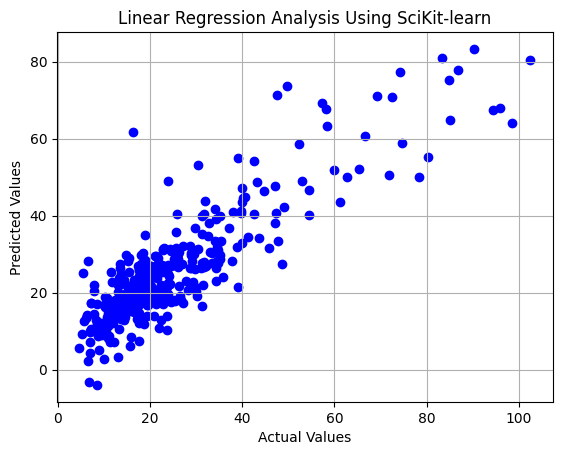

In [7]:
plt.scatter(y_test, y_pred, color='blue', label='Actual vs. Predicted')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression Analysis Using SciKit-learn")
plt.grid(True)
plt.show()


#### My implementation of linear regression

In [8]:
# Now, without library

# add column of all 1s
x['Ones'] = 1

# redo spliting because of the new column
x_train_mine, x_test_mine = x[:split], x[split:]
y_train_mine, y_test_mine = y[:split], y[split:]

In [9]:
# calculates beta from y_pred = x * beta formula
def calculateBeta(x, y):   
    xtx_inv = np.linalg.inv(np.dot(x.T, x))  # (X^T X)^(-1)
    xty = np.dot(x.T, y)  # X^T y
    beta = np.dot(xtx_inv, xty)  # (X^T X)^(-1) X^T y
    return beta


In [10]:
# Calculate beta using training data
beta = calculateBeta(x_train_mine, y_train_mine) 

# Predict using the training set and test set
y_train_pred_mine = np.dot(x_train_mine, beta)
y_test_pred_mine = np.dot(x_test_mine, beta)


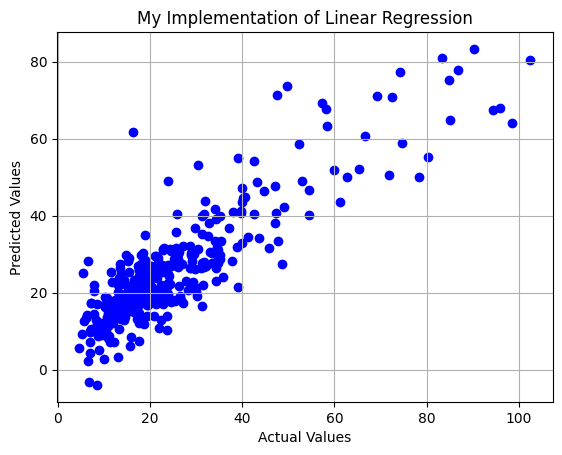

In [11]:
plt.scatter(y_test, y_test_pred_mine, color='blue', label='Actual vs. Predicted')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("My Implementation of Linear Regression")
plt.grid(True)
plt.show()


#### Comparing the two implementations

In [ ]:
mae_scikit = mean_absolute_error(y_test, y_pred)
mse_scikit = mean_squared_error(y_test, y_pred)
r2_scikit = r2_score(y_test, y_pred)

print(f"MAE Scikit: {mae_scikit}")
print(f"MSE  Scikit: {mse_scikit}")
print(f"R2  Scikit: {r2_scikit}")


mae_mine = mean_absolute_error(y_test_mine, y_test_pred_mine)
mse_mine = mean_squared_error(y_test_mine, y_test_pred_mine)
r2_mine = r2_score(y_test_mine, y_test_pred_mine)

print(f"MAE with my implementation: {mae_mine}")
print(f"MSE with my implementation: {mse_mine}")
print(f"R2 with my implementation: {r2_mine}")


MAE Scikit: 6.041491247227988
MSE  Scikit: 69.9312296540761
R2  Scikit: 0.7676374067779344
MAE with my implementation: 6.041491247228126
MSE with my implementation: 69.93122965407703
R2 with my implementation: 0.7676374067779312


#### Diagnosing my implementation with diagnostic plots

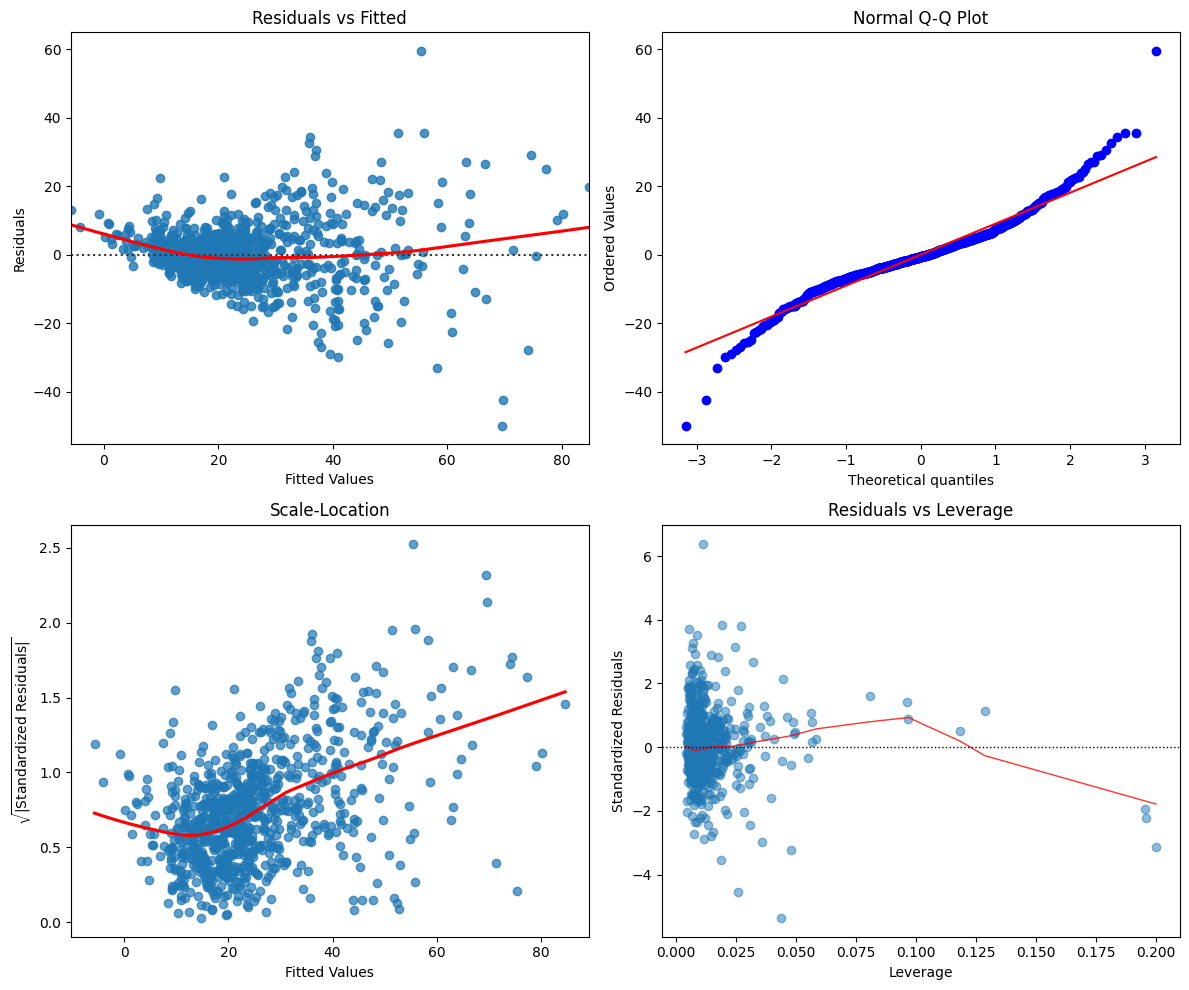

In [13]:
# Calculate residuals and standardized them
residuals = y_train_mine - y_train_pred_mine
standardized_residuals = residuals / np.std(residuals)

# Calculate leverage values for Residuals vs Leverage plot:
# hat matrix: H = X(X^TX)^-1X^T, and leverage is the diagonal of this matrix
H = np.dot(x_train_mine, np.linalg.inv(np.dot(x_train_mine.T, x_train_mine))).dot(x_train_mine.T)
leverage = np.diag(H)

# 2x2 grid
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Residual plot
sns.residplot(x=y_train_pred_mine, y=residuals, lowess=True, line_kws={'color': 'red'}, ax=axs[0, 0])
axs[0, 0].set_xlabel("Fitted Values")
axs[0, 0].set_ylabel("Residuals")
axs[0, 0].set_title("Residuals vs Fitted")

# Q-Q plot 
stats.probplot(residuals, dist="norm", plot=axs[0, 1])
axs[0, 1].set_title("Normal Q-Q Plot")

# Scale-Location plot
sqrt_abs_standardized_residuals = np.sqrt(np.abs(standardized_residuals)) 
axs[1, 0].scatter(y_train_pred_mine, sqrt_abs_standardized_residuals, alpha=0.7)
sns.regplot(x=y_train_pred_mine, y=sqrt_abs_standardized_residuals, lowess=True, line_kws={'color': 'red'}, scatter=False, ax=axs[1, 0])
axs[1, 0].set_xlabel("Fitted Values")
axs[1, 0].set_ylabel(r'$\sqrt{|\mathrm{Standardized\ Residuals}|}$')
axs[1, 0].set_title("Scale-Location")

# Residuals vs Leverage plot
axs[1, 1].scatter(leverage, standardized_residuals, alpha=0.5)
sns.regplot(x=leverage, y=standardized_residuals, scatter=False, ci=False, lowess=True, line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8}, ax=axs[1, 1])
axs[1, 1].axhline(0, ls='dotted', color='black', lw=1)
axs[1, 1].set_title('Residuals vs Leverage')
axs[1, 1].set_xlabel('Leverage')
axs[1, 1].set_ylabel('Standardized Residuals')


plt.tight_layout()
plt.show()


From Residuals vs Fitted plot we can see that the points aren't completely random, there is a curved trend, which could mean that some of the relationships within the dataset aren't linear but non-linear.

Normal Q-Q plot shows majority of the points close to the red line which would suggest normality but there are also some deviations on the tails of the line.

For the Scale-Location plot we can say that the spread of residuals increases with fitted values, forming an upward trend, which indicates heteroscedasticity instead of homoscedasticity.

Lastly, on the Residuals vs Leverage we see some points which have larger leverage so we can assume that these points might be influential.

#### Trying to make improvements to the model

First, trying with correlation matrix. 
That should help me better see the relationships between the attributes and target.

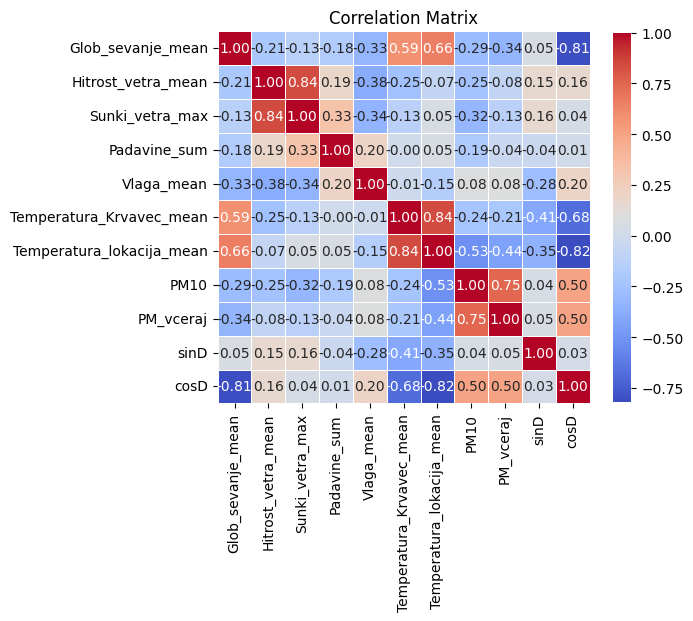

In [14]:
correlation_matrix = df.corr()

plt.figure(figsize=(6, 6))

# Creating a heatmap
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8}, linewidths=.5)           
plt.title("Correlation Matrix", fontsize=12)
plt.show()

From correlation matrix we see that highest correlations between target PM10 are with following columns:
- cosD
- PM_vceraj
- Temperatura_lokacija_mean 
- Sunki_vetra_max

So let's try using only those columns as attributes:

In [15]:
x_corr = df.loc[:,['cosD','PM_vceraj', 'Temperatura_lokacija_mean', 'Sunki_vetra_max']]
x_corr['Ones'] = 1

x_train_corr, x_test_corr = x_corr[:split], x_corr[split:]
y_train_corr, y_test_corr = y[:split], y[split:]


beta_corr = calculateBeta(x_train_corr, y_train_corr)

y_train_pred_corr = np.dot(x_train_corr, beta_corr)
y_test_pred_corr = np.dot(x_test_corr, beta_corr)

In the following results we can see that this doesn't help our model, as it gives worse results for each metric.

Even if I add more attributes ('Sunki_vetra_max', 'Glob_sevanje_mean', 'Hitrost_vetra_mean', 'Padavine_sum'),
based on their correlation scores, the results are never better then the original for all 3 metrics.

In [16]:
mae_corr = mean_absolute_error(y_test_corr, y_test_pred_corr)
mse_corr = mean_squared_error(y_test_corr, y_test_pred_corr)
r2 = r2_score(y_test_corr, y_test_pred_corr)

print(f"MAE original: {mae_mine}")
print(f"MSE original: {mse_mine}")
print(f"R2 original: {r2_mine}",  end="\n\n")

print(f"MAE after taking into consideration correlations: {mae_corr}")
print(f"MSE after taking into consideration correlations: {mse_corr}")
print(f"R2 after taking into consideration correlations: {r2}")



MAE original: 6.041491247228126
MSE original: 69.93122965407703
R2 original: 0.7676374067779312

MAE after taking into consideration correlations: 6.4880186226836525
MSE after taking into consideration correlations: 79.15952626472041
R2 after taking into consideration correlations: 0.7369742689770001


I will also try ridge regression which has a regularization term in the cost function.

The formula for Ridge regression coefficients is y_pred = X*beta where beta = (X^T X + λI)^(-1) X^T y so I will just adjust beta formula from my initial implementation

In [17]:
def calculateRidgeBeta(x, y, lambda_):
    n,m = x.shape
    I = np.eye(m)  # Create an identity matrix of size (m, m)
   
    xtx_inv = np.linalg.inv(np.dot(x.T, x) + lambda_ * I)  # (X^T X + λI)^(-1)
    xty = np.dot(x.T, y)  # X^T y
    return np.dot(xtx_inv, xty)


We see in the following validation results that this produces better results for all three metrics. The improvements are small, but they do exist.

In [43]:
# Calculate beta with new formula
beta_ridge = calculateRidgeBeta(x_train_mine, y_train_mine, 1.0)

# Make predictions
y_train_pred_ridge = np.dot(x_train_mine,beta_ridge)
y_test_pred_ridge = np.dot(x_test_mine,beta_ridge)


mae_ridge = mean_absolute_error(y_test_mine, y_test_pred_ridge)
mse_ridge = mean_squared_error(y_test_mine, y_test_pred_ridge)
r2_ridge = r2_score(y_test_mine, y_test_pred_ridge)

print(f"MAE original: {mae_mine}")
print(f"MSE original: {mse_mine}")
print(f"R2 original: {r2_mine}", end="\n\n")

print(f"MAE after Ridge regression: {mae_ridge}")
print(f"MSE after Ridge regression: {mse_ridge}")
print(f"R2 after Ridge regression: {r2_ridge}")

MAE original: 6.041491247228126
MSE original: 69.93122965407703
R2 original: 0.7676374067779312

MAE after Ridge regression: 5.993425164997525
MSE after Ridge regression: 69.42930265668984
R2 after Ridge regression: 0.7693051746592909


From  Residuals vs Fitted plot we can see that data points aren't quite random, but rather make a curve. This indicates a non-linear relationship between attributes and target variable. This is why I will try to use Polynomial Features to see if this will help the model. I will use my Ridge model since it performed better as we have seen above.

We see in the following chunk, the results are better when we introduce Polynomial Features, so this did help my model.

In [42]:
# Generate polynomial and interaction terms
poly = PolynomialFeatures(degree=2, include_bias=False)
x_train_poly = poly.fit_transform(x_train_mine)
x_test_poly = poly.transform(x_test_mine)


# Predict with Ridge model
beta_ridge_poly = calculateRidgeBeta(x_train_poly, y_train_mine, 1.0)

y_train_pred_poly = np.dot(x_train_poly, beta_ridge_poly)
y_test_pred_poly = np.dot(x_test_poly, beta_ridge_poly)


mae_poly = mean_absolute_error(y_test_mine, y_test_pred_poly)
mse_poly = mean_squared_error(y_test_mine, y_test_pred_poly)
r2_poly = r2_score(y_test_mine, y_test_pred_poly)

print(f"MAE original: {mae_mine}")
print(f"MSE original: {mse_mine}")
print(f"R2 original: {r2_mine}", end="\n\n")

# Display results
print(f"MAE with polynomial features: {mae_poly}")
print(f"MSE with polynomial features: {mse_poly}")
print(f"R2 with polynomial features: {r2_poly}")


MAE original: 6.041491247228126
MSE original: 69.93122965407703
R2 original: 0.7676374067779312

MAE with polynomial features: 5.5356005543033975
MSE with polynomial features: 62.21871450710185
R2 with polynomial features: 0.7932640120683068


From Residuals vs Leverage plot we saw that there might be some outliers in our dataset. So I will use the Interquartile Range (IQR) to find and remove them and see if the model performes better. 

In [62]:
from sklearn.model_selection import train_test_split

data = df

# Function to remove outliers using IQR
def remove_outliers_iqr(df, feature_columns):
    for col in feature_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    return df

feature_columns = [col for col in df.columns if col != 'PM10']
df_cleaned = remove_outliers_iqr(df, feature_columns)

# features and target variable
x_iqr = df_cleaned[feature_columns]
y_iqr = df_cleaned['PM10']

# Split the data into training and testing sets
x_train_iqr, x_test_iqr, y_train_iqr, y_test_iqr = train_test_split(x_iqr, y_iqr, test_size=0.3, random_state=42)

# Make predictions
beta_iqr = calculateRidgeBeta(x_train_iqr, y_train_iqr, 1.0)

y_train_pred_iqr = np.dot(x_train_iqr, beta_iqr)
y_test_pred_iqr = np.dot(x_test_iqr, beta_iqr)


We see that there is quite an improvement from the original results when the outliers are removed, so this did help the model.

In [66]:
mae = mean_absolute_error(y_test_iqr, y_test_pred_iqr)
mse = mean_squared_error(y_test_iqr, y_test_pred_iqr)
r2 = r2_score(y_test_iqr, y_test_pred_iqr)

print(f"MAE original: {mae_mine}")
print(f"MSE original: {mse_mine}")
print(f"R2 original: {r2_mine}", end="\n\n")

print("MAE after removing outliers:", mae)
print("MSE after removing outliers:", mse)
print("R2 after removing outliers:", r2)


MAE original: 6.041491247228126
MSE original: 69.93122965407703
R2 original: 0.7676374067779312

MAE after removing outliers: 5.509726028379241
MSE after removing outliers: 64.87334378216943
R2 after removing outliers: 0.6297480012207625


Using scaling didn't work for me, it gave much worse performance.